# Assignment 09, Problem 5 — Hussein Jawad
**E89 Deep Learning · Speech command recognition: a transformer on MFCC arrays** (based on Lecture 9, the lab notebook
`02_lab09_speech_cnn_transformer.ipynb` and Problem 4)

---

# Problem 5: A transformer instead of the CNN
In the attached notebook `lab09_speech_cnn_transformer.ipynb` you have an example of the use of the transformer model
for classification of words. Make a copy of the notebook developed in Problem 4 and apply the transformer model from the
above notebook instead of the CNN model. Determine loss and accuracy curves and evaluate the transformer model on the test
dataset. What is the number of trainable parameters in this model.

## Approach

### Goal
Keep everything from Problem 4 (the same 12 × 33 MFCC arrays, DataLoaders, training, plots and test) but replace the
2-layer Conv2D CNN with the **transformer** from the lab notebook: each of the 33 frames becomes a token, and two
self-attention layers compare all frames with each other before the word is classified.

### Input: one MFCC array per recording (as in Problem 2)

| | Value |
|---|---|
| Recording | 1 s at 16 kHz (shorter recordings padded with zeros) |
| Frames | 25 ms, stride 10 ms, Hann window → 98 frames |
| MFCCs | first 12 ($c_0 \dots c_{11}$), 40 mel filters |
| Every 3rd frame | 33 frames → array of **12 × 33** |

### Steps

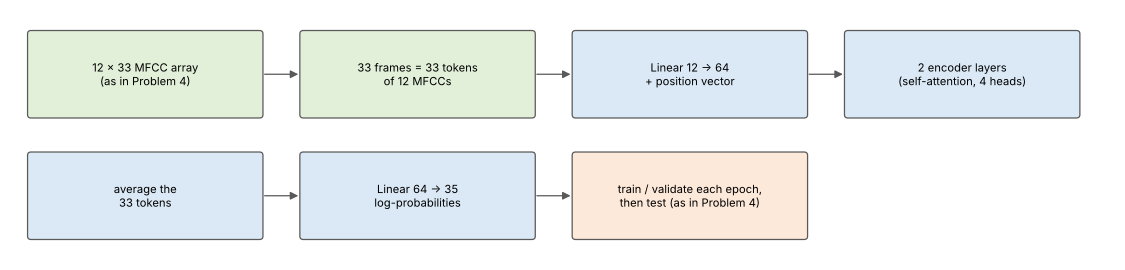

1. **Load** the dataset, labels and MFCC arrays, and build the DataLoaders, as in Problem 4 (Steps 2–5).
2. **Build** the lab notebook's transformer and count its trainable parameters (Step 6).
3. **Train** for 25 epochs with validation after each epoch, **plot** the loss and accuracy curves and **test**
   (Steps 7–11).

### Changes to the Problem 4 notebook
* Model: the lab notebook's `SmallMFCCTransformer` (64-number tokens, learned positions, 2 encoder layers with 4
  attention heads) instead of the 2-layer Conv2D CNN. Its input layer takes 12 MFCCs (the lab used 13) and it has 33
  position vectors, one per frame. It returns log-probabilities, so the training code with `nll_loss` is unchanged
  (log-softmax + negative log-likelihood = the lab's cross-entropy).
* Optimizer: the lab notebook's AdamW (learning rate 0.001, weight decay 0.0001), which suits transformers better than
  the CNN's learning rate of 0.01. The schedule, batch size, epochs, data, plots and test are the same as in Problem 4.

## Solution

### Step 1: Imports and device

In [1]:
import os                                    # file paths
import numpy as np                           # numerical arrays
import soundfile as sf                       # reads the .wav files
import librosa                               # MFCCs, as in Problem 2
import torch                                 # PyTorch
import torch.nn as nn                        # neural-network layers
import torch.nn.functional as F              # relu, log_softmax, nll_loss, ...
import torch.optim as optim                  # optimizers and learning-rate schedulers
from torch.utils.data import TensorDataset, DataLoader  # data sets and loaders built from tensors
from torchaudio.datasets import SPEECHCOMMANDS  # the Speech Commands dataset
import matplotlib.pyplot as plt              # plotting

torch.manual_seed(0)                         # same initial weights and batch order on every run
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # use the GPU when there is one
print("torch:", torch.__version__, "| librosa:", librosa.__version__, "| device:", device)  # what was used

torch: 2.15.0+cu132 | librosa: 1.0.0 | device: cpu


### Step 2: The dataset (as in Problems 3–4)

In [2]:
class SubsetSC(SPEECHCOMMANDS):                                   # the class notebook's dataset with the official splits
    def __init__(self, subset: str = None):                        # subset = "training", "validation" or "testing"
        super().__init__("./", download=True)                      # downloads and unpacks the data only if not there yet

        def load_list(filename):                                   # reads one of the official split lists
            filepath = os.path.join(self._path, filename)          # e.g. ./SpeechCommands/.../validation_list.txt
            with open(filepath) as fileobj:                        # open the list
                return [os.path.normpath(os.path.join(self._path, line.strip()))  # full path of every file
                        for line in fileobj]                       # one file per line

        if subset == "validation":                                 # validation files:
            self._walker = load_list("validation_list.txt")        # from the official list
        elif subset == "testing":                                  # test files:
            self._walker = load_list("testing_list.txt")           # from the official list
        elif subset == "training":                                 # training files = all the others
            excludes = set(load_list("validation_list.txt") + load_list("testing_list.txt"))  # files to leave out
            self._walker = [w for w in self._walker if os.path.normpath(w) not in excludes]  # keep the rest

    def __getitem__(self, n):                                      # one data point: (waveform, sample rate, label)
        path = self._walker[n]                                     # path of the n-th recording
        waveform, sample_rate = sf.read(path, dtype="float32")     # read the samples with soundfile
        label = os.path.basename(os.path.dirname(path))            # the word = name of its folder
        return torch.from_numpy(waveform).unsqueeze(0), sample_rate, label  # waveform shape [1, samples]


train_set = SubsetSC("training")             # training recordings
validation_set = SubsetSC("validation")      # validation recordings
test_set = SubsetSC("testing")               # test recordings
print(f"training: {len(train_set)} | validation: {len(validation_set)} | testing: {len(test_set)}")  # sizes

training: 84843 | validation: 9981 | testing: 11005


### Step 3: The labels (label-listing cell disabled, as in Problems 3–4)

In [3]:
# DISABLED: the class notebook's label-listing cell (it decodes all 84,843 training recordings)
# labels = sorted(list(set(datapoint[2] for datapoint in train_set)))
# labels

In [4]:
labels = sorted(d for d in os.listdir(train_set._path)          # the labels are the word-folder names,
                if os.path.isdir(os.path.join(train_set._path, d)) and not d.startswith("_"))  # not _background_noise_
print(len(labels), "labels:", labels)        # 35 words

35 labels: ['backward', 'bed', 'bird', 'cat', 'dog', 'down', 'eight', 'five', 'follow', 'forward', 'four', 'go', 'happy', 'house', 'learn', 'left', 'marvin', 'nine', 'no', 'off', 'on', 'one', 'right', 'seven', 'sheila', 'six', 'stop', 'three', 'tree', 'two', 'up', 'visual', 'wow', 'yes', 'zero']


### Step 4: MFCC arrays of every 3rd frame (as in Problem 4)
Each recording is cut or padded to 1 s, and `librosa.feature.mfcc` computes 12 MFCCs with the Problem 2 settings
(25 ms Hann frames, 10 ms stride, 40 mel filters); every 3rd frame is kept. The recordings are processed 1,000 at a time.
Then each coefficient is scaled to mean 0 and standard deviation 1 using **training** statistics only (otherwise $c_0$,
around −300, would dominate the inputs).

In [5]:
def mfcc_arrays(dataset):                                      # 12 MFCCs of every 3rd frame for each recording
    X, y = [], []                                              # MFCC arrays and label numbers
    for start in range(0, len(dataset), 1000):                 # 1,000 recordings at a time
        waves, targets = [], []                                # one block of recordings
        for i in range(start, min(start + 1000, len(dataset))):  # each recording of the block
            waveform, sample_rate, label = dataset[i]          # samples (16 kHz), sample rate, word
            w = waveform[0, :16000].numpy()                    # at most 1 s
            waves.append(np.pad(w, (0, 16000 - len(w))))       # shorter recordings: zeros up to 1 s
            targets.append(labels.index(label))                # label number
        m = librosa.feature.mfcc(y=np.stack(waves), sr=16000, n_mfcc=12,   # Problem 2 settings: 12 MFCCs,
                                 n_fft=400, win_length=400, hop_length=160, # 25 ms frames every 10 ms,
                                 window="hann", center=False, n_mels=40)    # Hann window, 40 mel filters
        X.append(m[:, :, ::3])                                 # every 3rd frame -> [block, 12, 33]
        y += targets                                           # labels of the block
    return torch.tensor(np.concatenate(X)).unsqueeze(1), torch.tensor(y)  # [N, 1, 12, 33] and [N]

X_train, y_train = mfcc_arrays(train_set)                      # training arrays
X_val, y_val = mfcc_arrays(validation_set)                     # validation arrays
X_test, y_test = mfcc_arrays(test_set)                         # test arrays

mean = X_train.mean(dim=(0, 3), keepdim=True)                  # mean of each coefficient (training data only)
std = X_train.std(dim=(0, 3), keepdim=True)                    # standard deviation of each coefficient
X_train, X_val, X_test = [(X - mean) / std for X in (X_train, X_val, X_test)]  # same scaling for all three sets
print("MFCC arrays [recordings, channel, MFCCs, frames]:",   # shapes of the three sets
      tuple(X_train.shape), tuple(X_val.shape), tuple(X_test.shape))  # training, validation, test

MFCC arrays [recordings, channel, MFCCs, frames]: (84843, 1, 12, 33) (9981, 1, 12, 33) (11005, 1, 12, 33)


### Step 5: DataLoaders for training, validation and testing (as in Problem 4)

In [6]:
batch_size = 256                                               # as in Problems 3-4
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True)   # random order
validation_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=batch_size)               # validation
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=batch_size)                   # test
print("batches per epoch:", len(train_loader))                 # 332 training batches

batches per epoch: 332


### Step 6: The transformer (lab notebook)
Each frame (12 MFCCs) is projected to a 64-number token and a learned position vector is added. Two transformer encoder
layers (4 attention heads each) let every frame look at all the others. The tokens are averaged and a linear layer gives
the 35 word scores.

In [7]:
class SmallMFCCTransformer(nn.Module):                         # the lab notebook's transformer
    def __init__(self, n_classes=35, n_mfcc=12, max_frames=33,  # 12 MFCCs x 33 frames in, 35 words out
                 d_model=64, nhead=4, num_layers=2):           # token size, attention heads, encoder layers
        super().__init__()                                     # set up the nn.Module
        self.projection = nn.Linear(n_mfcc, d_model)           # each frame (12 MFCCs) -> a token of 64 numbers
        self.position = nn.Parameter(torch.zeros(1, max_frames, d_model))  # one learned position vector per frame
        nn.init.normal_(self.position, std=0.02)               # small random starting values
        self.blocks = nn.ModuleList([                          # the encoder layers:
            nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead,     # self-attention with 4 heads,
                                       dim_feedforward=128, dropout=0.1,  # a feed-forward network, dropout,
                                       activation="gelu", batch_first=True)  # GELU, input [batch, frames, 64]
            for _ in range(num_layers)])                       # 2 independent layers
        self.norm = nn.LayerNorm(d_model)                      # layer normalization at the end
        self.head = nn.Linear(d_model, n_classes)              # 64 -> 35 word scores

    def forward(self, x):                                      # x: [batch, 1, 12, 33]
        x = x.squeeze(1).transpose(1, 2)                       # -> [batch, 33 frames, 12 MFCCs]
        x = self.projection(x) + self.position[:, :x.shape[1]] # tokens + positions -> [batch, 33, 64]
        for block in self.blocks:                              # the two encoder layers
            x = block(x)                                       # self-attention + feed-forward
        x = self.norm(x).mean(dim=1)                           # average over the 33 frames -> [batch, 64]
        return F.log_softmax(self.head(x), dim=1)              # log-probabilities of the 35 words


model = SmallMFCCTransformer(n_classes=len(labels)).to(device) # create the model on the GPU/CPU
print(model)                                                   # show the layers
print("Number of trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))  # size

SmallMFCCTransformer(
  (projection): Linear(in_features=12, out_features=64, bias=True)
  (blocks): ModuleList(
    (0-1): 2 x TransformerEncoderLayer(
      (self_attn): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
      )
      (linear1): Linear(in_features=64, out_features=128, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (linear2): Linear(in_features=128, out_features=64, bias=True)
      (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (dropout1): Dropout(p=0.1, inplace=False)
      (dropout2): Dropout(p=0.1, inplace=False)
    )
  )
  (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
  (head): Linear(in_features=64, out_features=35, bias=True)
)
Number of trainable parameters: 72291


### Step 7: Optimizer (lab notebook)

In [8]:
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.0001)  # the lab notebook's optimizer
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=20, gamma=0.1)    # same schedule as in Problems 3-4

### Step 8: Training and evaluation functions (as in Problem 4)

In [9]:
def number_of_correct(pred, target):                           # number of correct predictions
    return pred.squeeze().eq(target).sum().item()              # compare predicted and true labels

def get_likely_index(tensor):                                  # most likely word for each recording
    return tensor.argmax(dim=-1)                               # index of the largest log-probability

def train(model):                                              # one epoch on the training set
    model.train()                                              # training mode
    total_loss, correct = 0.0, 0                               # sums over the epoch
    for data, target in train_loader:                          # one batch at a time
        data, target = data.to(device), target.to(device)      # move the batch to the GPU/CPU
        output = model(data)                                   # run the transformer on the MFCC arrays
        loss = F.nll_loss(output.squeeze(), target)            # negative log-likelihood
        optimizer.zero_grad()                                  # clear the old gradients
        loss.backward()                                        # backpropagation
        optimizer.step()                                       # update the weights
        total_loss += loss.item() * len(target)                # add up the loss of this batch
        correct += number_of_correct(get_likely_index(output), target)  # and its correct predictions
    n = len(train_loader.dataset)                              # number of training recordings
    return total_loss / n, correct / n                         # average loss and accuracy of the epoch

@torch.no_grad()                                               # no gradients needed for evaluation
def evaluate(model, loader):                                   # loss and accuracy on a validation or test set
    model.eval()                                               # evaluation mode
    total_loss, correct = 0.0, 0                               # sums over the data set
    for data, target in loader:                                # one batch at a time
        data, target = data.to(device), target.to(device)      # move the batch to the GPU/CPU
        output = model(data)                                   # run the model
        total_loss += F.nll_loss(output.squeeze(), target, reduction="sum").item()  # summed loss of the batch
        correct += number_of_correct(get_likely_index(output), target)              # correct predictions
    n = len(loader.dataset)                                    # number of recordings
    return total_loss / n, correct / n                         # average loss and accuracy

### Step 9: Train, validating at the end of every epoch (25 epochs, as in Problems 3–4)

In [10]:
n_epoch = 25                                               # same number of epochs as in Problems 3-4
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}  # one value per epoch

for epoch in range(1, n_epoch + 1):                            # one epoch at a time
    train_loss, train_acc = train(model)                       # train on all training arrays
    val_loss, val_acc = evaluate(model, validation_loader)     # check the current model on the validation set
    scheduler.step()                                           # learning-rate schedule
    for key, value in zip(history, (train_loss, train_acc, val_loss, val_acc)):  # store the four numbers
        history[key].append(value)                             # of this epoch
    print(f"Epoch {epoch:2d}: train loss {train_loss:.3f}, accuracy {train_acc:.1%} | "  # progress line
          f"validation loss {val_loss:.3f}, accuracy {val_acc:.1%}")                     # for each epoch

Epoch  1: train loss 1.766, accuracy 50.7% | validation loss 0.902, accuracy 74.6%


Epoch  2: train loss 0.849, accuracy 76.2% | validation loss 0.651, accuracy 81.4%


Epoch  3: train loss 0.650, accuracy 81.5% | validation loss 0.522, accuracy 85.2%


Epoch  4: train loss 0.538, accuracy 84.6% | validation loss 0.456, accuracy 86.9%


Epoch  5: train loss 0.467, accuracy 86.4% | validation loss 0.395, accuracy 88.4%


Epoch  6: train loss 0.419, accuracy 87.8% | validation loss 0.368, accuracy 89.2%


... (15 outputs left out)

Epoch 22: train loss 0.183, accuracy 94.4% | validation loss 0.274, accuracy 92.3%


Epoch 23: train loss 0.180, accuracy 94.5% | validation loss 0.275, accuracy 92.3%


Epoch 24: train loss 0.179, accuracy 94.7% | validation loss 0.276, accuracy 92.3%


Epoch 25: train loss 0.177, accuracy 94.6% | validation loss 0.274, accuracy 92.3%


### Step 10: Accuracy and loss curves

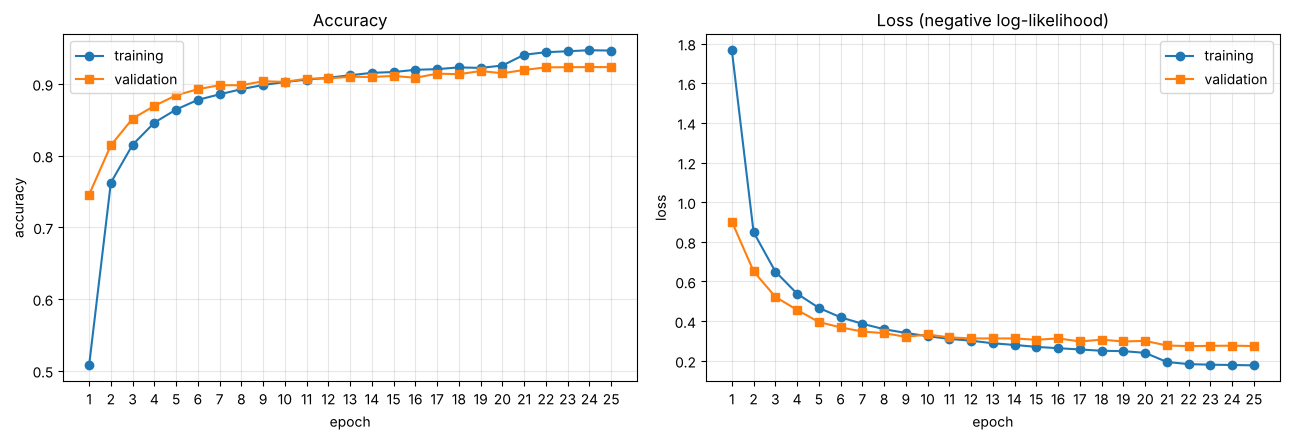

In [11]:
epochs = range(1, n_epoch + 1)                                 # x axis: epoch numbers
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))                # two diagrams side by side
ax[0].plot(epochs, history["train_acc"], "o-", label="training")      # training accuracy
ax[0].plot(epochs, history["val_acc"], "s-", label="validation")      # validation accuracy
ax[0].set_title("Accuracy")                                    # first diagram: accuracy
ax[0].set_ylabel("accuracy")                                   # vertical axis label
ax[1].plot(epochs, history["train_loss"], "o-", label="training")     # training loss
ax[1].plot(epochs, history["val_loss"], "s-", label="validation")     # validation loss
ax[1].set_title("Loss (negative log-likelihood)")              # second diagram: loss
ax[1].set_ylabel("loss")                                       # vertical axis label
for axis in ax:                                                # common settings
    axis.set_xlabel("epoch")                                   # horizontal axis label
    axis.set_xticks(list(epochs))                              # one tick per epoch
    axis.grid(alpha=0.3)                                       # light grid
    axis.legend()                                              # training vs validation
plt.tight_layout()                                             # avoid overlapping labels
plt.show()                                                     # render the figure

### Step 11: Accuracy on the test set

In [12]:
test_loss, test_acc = evaluate(model, test_loader)             # the final model on the 11,005 test recordings
print(f"Test accuracy: {test_acc:.1%} (loss {test_loss:.3f})")  # the actual accuracy of the model

Test accuracy: 91.7% (loss 0.300)


## Results and discussion

| After 25 epochs | Training | Validation | Test |
|---|---|---|---|
| Accuracy | 94.6% | 92.3% | **91.7%** |
| Loss | 0.177 | 0.274 | 0.300 |

**Number of trainable parameters: 72,291** (counted in Step 6; the breakdown is in A.2).

* **Smooth curves.** Validation accuracy rises steadily from 74.6% after epoch 1 to about 91% by epoch 13, without the
  jumps seen with the CNNs (this model is trained with the lab notebook's learning rate of 0.001 instead of 0.01).
* **Validation at first above training.** In the first 12 epochs the validation accuracy is at least as high as the
  training accuracy, because the training value is averaged over the epoch while the model is still improving, and
  dropout is active during training.
* **Learning-rate drop.** At epoch 21 the training loss drops further (0.240 → 0.194) but the validation loss only a
  little (0.300 → 0.277), so the gap between training and validation grows slightly; the validation loss does not rise.
* **Test accuracy 91.7%**, higher than the CNNs on the same data (85.9% in Problem 3, 84.3% in Problem 4), with about
  3.4 times as many parameters as the Problem 4 CNN; the 25 training epochs took 10.9 min on this computer's CPU (3.3 min
  for the Problem 4 CNN).

---
# Appendix: The ideas behind Problem 5

## A.1 Frames become tokens, and self-attention compares them
The transformer treats the 33 kept frames like the words of a sentence: each frame's 12 MFCCs are projected to a token of
64 numbers, and a learned position vector tells the model where in the recording the frame is. In each encoder layer,
**self-attention** lets every token look at all 33 tokens: for each pair it computes a weight (how relevant the other
frame is), and the token is updated with the weighted average of the others. With 4 heads, this is done 4 times in
parallel with different weights. A feed-forward network then processes each token on its own.

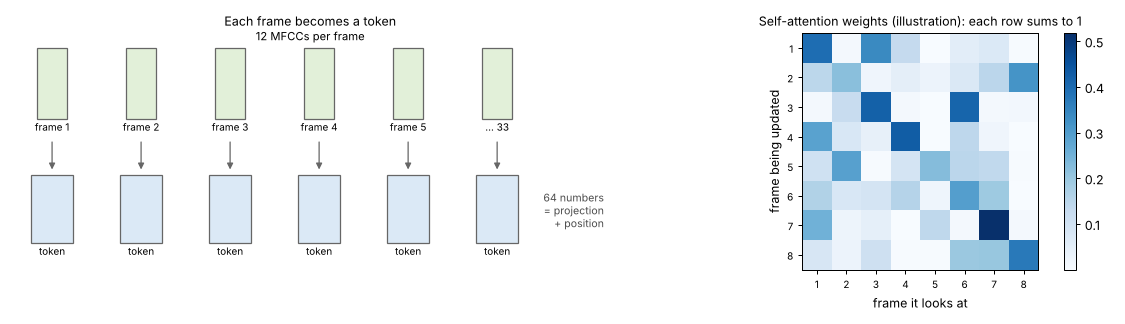

Unlike the CNN, whose 3 × 3 filters only see neighboring frames, attention can connect frames that are far apart (for
example the beginning and the end of a word) in a single layer.

## A.2 Counting the trainable parameters

| Part | Count | Parameters |
|---|---|---|
| Projection 12 → 64 | 12·64 weights + 64 biases | 832 |
| Position vectors | 33 frames × 64 | 2,112 |
| Encoder layer: attention | 3·(64·64 + 64) for queries, keys, values + (64·64 + 64) output | 16,640 |
| Encoder layer: feed-forward | (64·128 + 128) + (128·64 + 64) | 16,576 |
| Encoder layer: 2 layer norms | 2 × (64 + 64) | 256 |
| 2 encoder layers | 2 × 33,472 | 66,944 |
| Final layer norm | 64 + 64 | 128 |
| Head 64 → 35 | 64·35 weights + 35 biases | 2,275 |
| **Total** | | **72,291** |

Most parameters are in the two encoder layers; the model is about 3.4 times as large as the CNN of Problem 4 (21,283).